In [200]:
import pandas as pd 
import numpy as np

df = pd.read_csv("bank_customer.csv")
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42.0,2,0.00,1,1.0,1.0,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41.0,1,83807.86,1,0.0,1.0,112542.58,0
2,3,15619304,Onio,502,France,Female,42.0,8,159660.80,3,1.0,0.0,113931.57,1
3,4,15701354,Boni,699,France,Female,39.0,1,0.00,2,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43.0,2,125510.82,1,NaN,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9997,9998,15584532,Liu,709,France,Female,36.0,7,0.00,1,0.0,1.0,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1
9999,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1
10000,10000,15628319,Walker,792,France,Female,28.0,4,130142.79,1,1.0,0.0,38190.78,0


In [201]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          1
Gender             0
Age                1
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          1
IsActiveMember     1
EstimatedSalary    0
Exited             0
dtype: int64

In [202]:
df['Age'].fillna(df['Age'].median(), inplace=True)
df['HasCrCard'].fillna(df['HasCrCard'].median(), inplace=True)
df['IsActiveMember'].fillna(df['IsActiveMember'].median(), inplace=True)
df['Geography'].fillna(df['Geography'].mode()[0], inplace=True)

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1707/3008315050.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1707/3008315050.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values alwa

In [203]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [204]:
cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
df_select = df[cols]

q1 = df_select.quantile(0.25)
q3 = df_select.quantile(0.75)

iqr = q3 - q1 

lower = q1 - 1.5 * iqr 
upper = q3 + 1.5 * iqr 

df = df[~((df[cols] < lower) | (df[cols] > upper)).any(axis=1)]
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42.0,2,0.00,1,1.0,1.0,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41.0,1,83807.86,1,0.0,1.0,112542.58,0
2,3,15619304,Onio,502,France,Female,42.0,8,159660.80,3,1.0,0.0,113931.57,1
3,4,15701354,Boni,699,France,Female,39.0,1,0.00,2,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43.0,2,125510.82,1,1.0,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9997,9998,15584532,Liu,709,France,Female,36.0,7,0.00,1,0.0,1.0,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1
9999,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1
10000,10000,15628319,Walker,792,France,Female,28.0,4,130142.79,1,1.0,0.0,38190.78,0


In [205]:
from sklearn.preprocessing import LabelEncoder 
from sklearn.preprocessing import MinMaxScaler 

encode = LabelEncoder()

df["Gender"] = encode.fit_transform(df["Gender"])
df = pd.get_dummies(df, columns=["Geography"])
scaler = MinMaxScaler()
df[cols] = scaler.fit_transform(df[cols])
df

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1707/882228987.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Gender"] = encode.fit_transform(df["Gender"])


,RowNumber,CustomerId,Surname,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,1,15634602,Hargrave,0.505353,0,0.545455,0.2,0.000000,0.0,1.0,1.0,0.506735,1,True,False,False
1,2,15647311,Hill,0.481799,0,0.522727,0.1,0.334031,0.0,0.0,1.0,0.562709,0,False,False,True
2,3,15619304,Onio,0.254818,0,0.545455,0.8,0.636357,1.0,1.0,0.0,0.569654,1,True,False,False
3,4,15701354,Boni,0.676660,0,0.477273,0.1,0.000000,0.5,0.0,0.0,0.469120,0,True,False,False
4,5,15737888,Mitchell,1.000000,0,0.568182,0.2,0.500246,0.0,1.0,1.0,0.395400,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9997,9998,15584532,Liu,0.698073,0,0.409091,0.7,0.000000,0.0,0.0,1.0,0.210390,1,True,False,False
9998,9999,15682355,Sabbatini,0.832976,1,0.545455,0.3,0.299226,0.5,1.0,0.0,0.464429,1,False,True,False
9999,9999,15682355,Sabbatini,0.832976,1,0.545455,0.3,0.299226,0.5,1.0,0.0,0.464429,1,False,True,False
10000,10000,15628319,Walker,0.875803,0,0.227273,0.4,0.518708,0.0,1.0,0.0,0.190914,0,True,False,False


In [206]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=["RowNumber", "CustomerId","Surname", "Exited"])
y = df[["Exited"]]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42)

In [207]:
from sklearn.ensemble import RandomForestClassifier 

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

model.score(x_test, y_test)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


0.85423197492163

KNN (K-Nearest Neighbors)

KNN Regressor

In [208]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("death_clean.csv")
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [209]:
x = df[["Cause", "Type"]]
y = df[["Total Deaths"]]

x_encoded = pd.get_dummies(x, columns=["Cause", "Type"])

scaler = MinMaxScaler()
y_norm = scaler.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_norm, test_size=0.3, random_state=42)


In [210]:
knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(x_train, y_train)
y_pred = knn_model.predict(x_test)
y_pred

array([2.75668073e-01, 1.05016409e-01, 5.57899672e-02, 7.50117206e-02,
       1.10173465e-01, 1.10173465e-01, 1.05016409e-01, 4.17252696e-02,
       1.17205813e-02, 5.20393812e-02, 1.87529301e-03, 5.13830286e-01,
       1.05016409e-01, 1.57524613e-01, 3.16924519e-01, 1.05016409e-01,
       4.17252696e-02, 5.13830286e-01, 4.54758556e-02, 6.00093765e-02,
       2.95358650e-02, 1.33614627e-01, 1.41584623e-01, 4.21940928e-03,
       1.05016409e-01, 3.84435068e-02, 1.87529301e-03, 4.50070323e-02,
       6.09470230e-02, 6.09470230e-02, 5.62587904e-03, 5.15705579e-02,
       4.17252696e-02, 1.05016409e-01, 4.73511486e-02, 1.05016409e-01,
       5.13830286e-01, 1.33614627e-01, 4.87576184e-02, 4.87576184e-02,
       2.75668073e-01, 1.87529301e-03, 4.59446789e-02, 1.05016409e-01,
       4.73511486e-02, 1.60806376e-01, 1.10173465e-01, 6.09470230e-02,
       2.85982185e-02, 6.09470230e-02, 2.95358650e-02, 1.64088139e-02,
       1.87529301e-03, 4.17252696e-02, 1.17205813e-02, 4.68823254e-04,
      

In [211]:
score = knn_model.score(x_test, y_test)
score

0.633272646125455

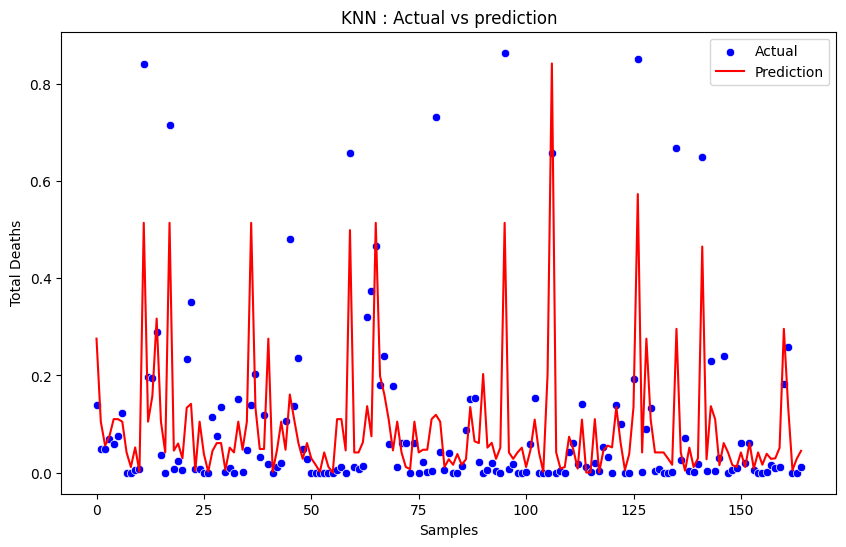

In [212]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=range(len(y_test)), y=y_test, color="blue", label="Actual")
sns.lineplot(x=range(len(y_test)), y=y_pred, color="red", label="Prediction")

plt.xlabel("Samples")
plt.ylabel("Total Deaths")
plt.title("KNN : Actual vs prediction")
plt.legend()
plt.show()

KNN Classifier

In [223]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix 

df = pd.read_csv("penyakit_jantung.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,female,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,female,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,male,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,female,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,male,0,120,354,0,1,163,1,0.6,2,0,2,1


In [214]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [215]:
from sklearn.preprocessing import LabelEncoder

cols = ['age', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal']

encode = LabelEncoder()
df["sex"] = encode.fit_transform(df["sex"])

scaler = MinMaxScaler()
df[cols] = scaler.fit_transform(df[cols])

In [216]:
x = df[cols]
y = df["target"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [217]:
knn_class = KNeighborsClassifier(n_neighbors=3)
knn_class.fit(x_train, y_train)
y_pred = knn_class.predict(x_test)
y_pred

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       0, 1, 1])

In [218]:
score = knn_class.score(x_test, y_test)
score

0.7692307692307693

In [219]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[34,  7],
       [14, 36]])

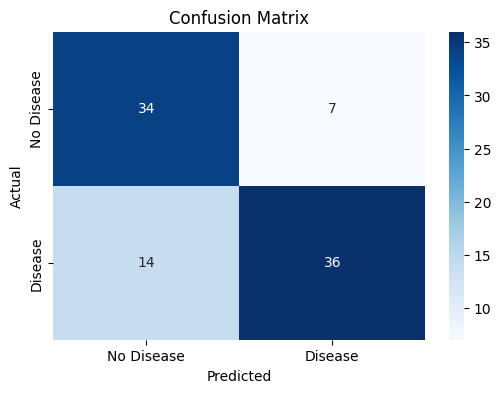

In [221]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,cmap="Blues", xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()